ПРАКТИЧЕСКАЯ РАБОТА №6
КОРРЕЛЯЦИОННЫЙ АНАЛИЗ
Данные загружены

1. КОРРЕЛЯЦИЯ ПИРСОНА


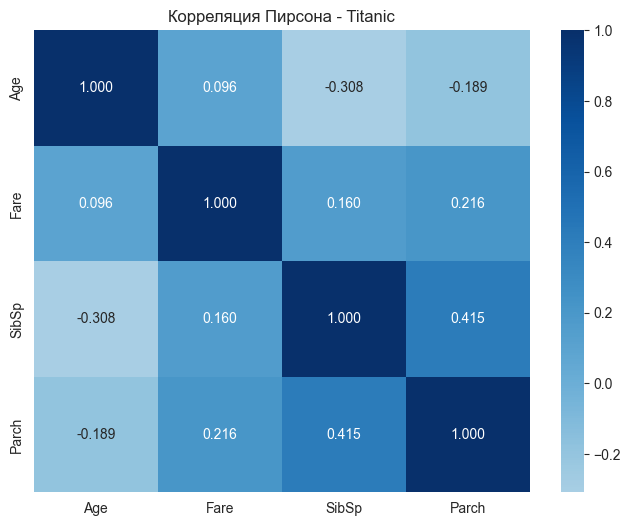

Возраст vs Цена билета: r=0.096, p=0.0102

2. КОРРЕЛЯЦИЯ СПИРМЕНА


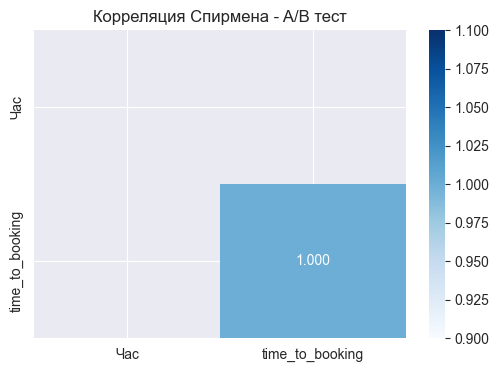

Час суток vs Время бронирования: r=nan, p=nan

3. ХИ-КВАДРАТ


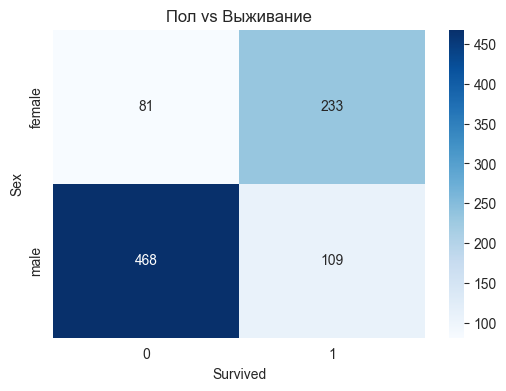

Хи-квадрат: χ²=260.7, p=0.0000

4. БИСЕРИАЛЬНАЯ КОРРЕЛЯЦИЯ
Ребенок vs Выживание: r=0.121, p=0.0003


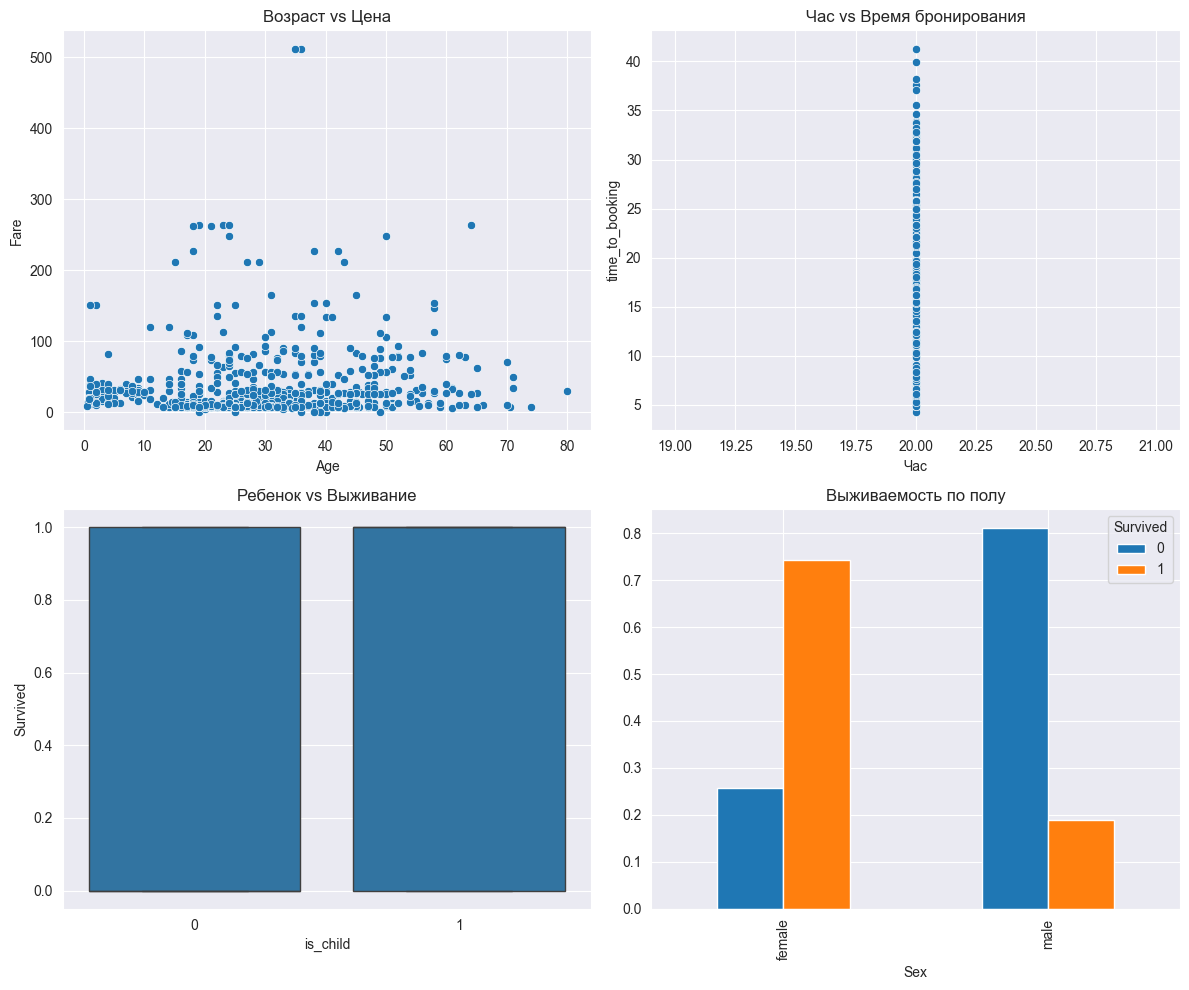


ИТОГОВЫЕ ВЫВОДЫ (α=0.05)
1. Возраст-Цена билета: r=0.096 (значима)
2. Час-Время бронирования: r=nan (не значима)
3. Пол-Выживание: χ²=260.7, сильная связь
4. Ребенок-Выживание: r=0.121 (значима)


In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr, chi2_contingency, pointbiserialr
import warnings
warnings.filterwarnings('ignore')

print("ПРАКТИЧЕСКАЯ РАБОТА №6")
print("КОРРЕЛЯЦИОННЫЙ АНАЛИЗ")
print("="*50)

# В связи с отсутствием датасета по ссылке используем несколько наших имеющихся
df_titanic = pd.read_csv("data/Titanic-Dataset.csv")
df_sessions = pd.read_csv("data/sessions_data.csv")
df_users = pd.read_csv("data/users_data.csv")

# Подготовка A/B данных
df_ab = df_sessions.merge(df_users, on='user_id', how='left')
df_ab['Бронирование'] = df_ab['booking_timestamp'].notna().astype(int)
df_ab['Час'] = df_ab['session_start_timestamp'].str[:2].astype(float)

print("Данные загружены")

# 1. МАТРИЦА КОРРЕЛЯЦИЙ ПИРСОНА
print("\n1. КОРРЕЛЯЦИЯ ПИРСОНА")
numeric_cols = ['Age', 'Fare', 'SibSp', 'Parch']
corr_pearson = df_titanic[numeric_cols].corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr_pearson, annot=True, cmap='Blues', center=0, fmt='.3f')
plt.title('Корреляция Пирсона - Titanic')
plt.show()

# ИСПРАВЛЕННАЯ проверка значимости (одинаковые индексы)
mask = df_titanic['Age'].notna() & df_titanic['Fare'].notna()
r_age_fare, p_age_fare = pearsonr(df_titanic.loc[mask, 'Age'], df_titanic.loc[mask, 'Fare'])
print(f"Возраст vs Цена билета: r={r_age_fare:.3f}, p={p_age_fare:.4f}")

# 2. КОРРЕЛЯЦИЯ СПИРМЕНА
print("\n2. КОРРЕЛЯЦИЯ СПИРМЕНА")
ab_mask = df_ab['Час'].notna() & df_ab['time_to_booking'].notna()
corr_spearman = df_ab.loc[ab_mask, ['Час', 'time_to_booking']].corr(method='spearman')
plt.figure(figsize=(6,4))
sns.heatmap(corr_spearman, annot=True, cmap='Blues', fmt='.3f')
plt.title('Корреляция Спирмена - A/B тест')
plt.show()

r_hour_time, p_hour_time = spearmanr(df_ab.loc[ab_mask, 'Час'], df_ab.loc[ab_mask, 'time_to_booking'])
print(f"Час суток vs Время бронирования: r={r_hour_time:.3f}, p={p_hour_time:.4f}")

# 3. ХИ-КВАДРАТ
print("\n3. ХИ-КВАДРАТ")
contingency = pd.crosstab(df_titanic['Sex'], df_titanic['Survived'])
plt.figure(figsize=(6,4))
sns.heatmap(contingency, annot=True, cmap='Blues', fmt='d')
plt.title('Пол vs Выживание')
plt.show()

chi2, p_chi, dof, _ = chi2_contingency(contingency)
print(f"Хи-квадрат: χ²={chi2:.1f}, p={p_chi:.4f}")

# 4. БИСЕРИАЛЬНАЯ КОРРЕЛЯЦИЯ
print("\n4. БИСЕРИАЛЬНАЯ КОРРЕЛЯЦИЯ")
df_titanic['is_child'] = (df_titanic['Age'] <= 16).astype(int)
r_biserial, p_biserial = pointbiserialr(df_titanic['is_child'], df_titanic['Survived'])
print(f"Ребенок vs Выживание: r={r_biserial:.3f}, p={p_biserial:.4f}")

# 5. ВИЗУАЛИЗАЦИЯ
fig, axes = plt.subplots(2, 2, figsize=(12,10))
sns.scatterplot(data=df_titanic[mask], x='Age', y='Fare', ax=axes[0,0])
axes[0,0].set_title('Возраст vs Цена')

sns.scatterplot(data=df_ab[ab_mask], x='Час', y='time_to_booking', ax=axes[0,1])
axes[0,1].set_title('Час vs Время бронирования')

sns.boxplot(data=df_titanic, x='is_child', y='Survived', ax=axes[1,0])
axes[1,0].set_title('Ребенок vs Выживание')

pd.crosstab(df_titanic['Sex'], df_titanic['Survived'], normalize='index').plot(kind='bar', ax=axes[1,1])
axes[1,1].set_title('Выживаемость по полу')
plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("ИТОГОВЫЕ ВЫВОДЫ (α=0.05)")
print("="*70)
print(f"1. Возраст-Цена билета: r={r_age_fare:.3f} {'(значима)' if p_age_fare<0.05 else '(не значима)'}")
print(f"2. Час-Время бронирования: r={r_hour_time:.3f} {'(значима)' if p_hour_time<0.05 else '(не значима)'}")
print(f"3. Пол-Выживание: χ²={chi2:.1f}, {'сильная связь' if p_chi<0.001 else 'слабая связь'}")
print(f"4. Ребенок-Выживание: r={r_biserial:.3f} {'(значима)' if p_biserial<0.05 else '(не значима)'}")
print("="*70)